# Try ReOpenly embeddings

Find the help-center passage that answers a question, visualize the texts, and check retrieval on four held-out questions. Use Python 3.12 or newer.

**The default run makes two billable embedding requests.** It starts no training and stores no feedback. Hosted comparison and reporting are optional and off by default. Keep keys out of cells and outputs; queries and passages are sent to the API.

The data is illustrative. Saved outputs show a real cloud run with the optional comparison and reporting enabled, not a promised quality gain. Capture provenance is in the notebook metadata.

## Setup

You need an API key and familiarity with Python lists, dictionaries and functions. In the checkout, select the kernel from `uv sync --locked`. A downloaded notebook needs no checkout.

Run the next cell first. It reuses the pinned packages when already installed; otherwise it installs them into this kernel with uv, or pip if uv is unavailable. If packages change, restart the kernel before continuing. If neither installer is available, [install uv](https://docs.astral.sh/uv/getting-started/installation/) first.


In [2]:
import importlib.util
from importlib.metadata import PackageNotFoundError, version
import shutil
import subprocess
import sys

requirements = ["openai==3.35.1", "numpy==2.5.4", "matplotlib==3.11.2", "httpx==0.28.1"]
needs_install = False
for requirement in requirements:
    name, expected = requirement.split("==")
    try:
        needs_install = needs_install or version(name) != expected
    except PackageNotFoundError:
        needs_install = True
if needs_install:
    if uv := shutil.which("uv"):
        command = [uv, "pip", "install", "--python", sys.executable]
    elif importlib.util.find_spec("pip") is not None:
        command = [sys.executable, "-m", "pip", "install"]
    else:
        raise RuntimeError("Install uv, restart the kernel, and rerun this cell.")
    subprocess.run([*command, *requirements], check=True)
    print("Dependencies installed. Restart the kernel before continuing.")


In [3]:
from datetime import datetime, timezone
from getpass import getpass
from uuid import uuid4
import os
import re
from typing import Literal

import httpx
import matplotlib.pyplot as plt
import numpy as np
from openai import OpenAI


Sign in and open **profile menu → [API keys](https://reopenly.com/app/api-keys)**. Create a key and copy its full value; it is shown only once. See the [API-key creation guide](https://reopenly.com/docs/getting-started/authentication/#create-an-account-api-key). The next cell prompts privately if `REOPENLY_API_KEY` is absent. Leave the optional model and reporting settings empty or disabled for the first run.

For the optional sections, `REOPENLY_PROJECT=owner/project` uses the slugs in the app URL. `REOPENLY_MODEL` selects a hosted model; `REOPENLY_REPORT_SEARCHES=1` and `REOPENLY_DATASET_ID` enable feedback writes.

In [4]:
MODEL = "ReOpenly/Qwen3-Embedding-0.6B"
BASE_URL = "https://reopenly.com/api"
PROJECT = os.getenv("REOPENLY_PROJECT", "")
DATASET_ID = os.getenv("REOPENLY_DATASET_ID", "")
YOUR_MODEL = os.getenv("REOPENLY_MODEL", "")
REPORT_SEARCHES = os.getenv("REOPENLY_REPORT_SEARCHES", "0") == "1"
API_KEY = os.getenv("REOPENLY_API_KEY") or getpass("ReOpenly API key: ")


In [5]:
if not API_KEY.strip():
    raise ValueError("An API key is required.")
client = OpenAI(
    api_key=API_KEY, base_url=f"{BASE_URL}/openai/v1", max_retries=0, timeout=300
)
print(f"Model: {MODEL}")


Model: ReOpenly/Qwen3-Embedding-0.6B


In [6]:
if YOUR_MODEL or REPORT_SEARCHES:
    if not re.fullmatch(r"[A-Za-z0-9_-]+/[A-Za-z0-9_-]+", PROJECT):
        raise ValueError("Set REOPENLY_PROJECT to owner/project before running the examples.")
if REPORT_SEARCHES:
    valid_id = DATASET_ID.isascii() and DATASET_ID.isdecimal()
    if not valid_id or int(DATASET_ID) < 1:
        raise ValueError("Choose a positive REOPENLY_DATASET_ID for reporting.")
if YOUR_MODEL and not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9._-]*", YOUR_MODEL):
    raise ValueError("REOPENLY_MODEL must be a hosted model slug.")


> **Note:** `embed()` preserves input order and normalizes vectors, so their dot product gives cosine similarity. Automatic retries are off: a lost response may already be billed.

In [7]:
def embed(
    texts: list[str], *, input_type: Literal["query", "document"],
model: str = MODEL, api: OpenAI = client
) -> np.ndarray:
    """Return normalized embeddings in the same order as the input texts."""
    response = api.embeddings.create(
        model=model, input=texts, extra_body={"input_type": input_type}
    )
    rows = sorted(response.data, key=lambda row: row.index)
    if [row.index for row in rows] != list(range(len(texts))):
        raise ValueError("The response did not match the inputs.")
    vectors = np.array([row.embedding for row in rows], dtype=float)
    lengths = np.linalg.norm(vectors, axis=1, keepdims=True)
    if not np.isfinite(vectors).all() or (lengths == 0).any():
        raise ValueError("The response contained an invalid vector.")
    return vectors / lengths


## 1 · Find the right passage

Each passage has an id. The questions below map to their expected answer ids; keep these evaluation questions out of training.

In [8]:
passages = {
    "refund-timeline": (
        "Refunds return to the original payment method within 5 to 7 business "
        "days after the return is received."
    ),
    "2fa-backup-codes": (
        "To sign in without your phone, use one of the backup codes you saved "
        "when you turned on two-factor authentication."
    ),
    "order-export": (
        "Export your orders as a CSV file from Orders > Export, after choosing "
        "a date range."
    ),
    "invoice-details": (
        "Add your company name under Settings > Billing; it appears on every "
        "invoice issued after the change."
    ),
}


In [9]:
test_questions = {
    "When will my refund show up on my card?": "refund-timeline",
    "lost my phone, cannot sign in": "2fa-backup-codes",
    "download all my orders as a spreadsheet": "order-export",
    "put my company on invoices": "invoice-details",
}


In [10]:
passage_ids = list(passages)
questions = list(test_questions)
expected_answers = list(test_questions.values())
document_vectors = embed(list(passages.values()), input_type="document")
query_vectors = embed(questions, input_type="query")
scores = query_vectors @ document_vectors.T


In [11]:
print(questions[0], "\n")
for index in np.argsort(-scores[0], stable=True):
    passage_id = passage_ids[index]
    print(f"{scores[0, index]:.3f}  {passage_id}: {passages[passage_id]}")


When will my refund show up on my card? 

0.610  refund-timeline: Refunds return to the original payment method within 5 to 7 business days after the return is received.
0.292  order-export: Export your orders as a CSV file from Orders > Export, after choosing a date range.
0.279  2fa-backup-codes: To sign in without your phone, use one of the backup codes you saved when you turned on two-factor authentication.
0.259  invoice-details: Add your company name under Settings > Billing; it appears on every invoice issued after the change.


Check whether the expected answer is first. Larger cosine scores mean closer vectors; they are not probabilities that an answer is correct.

## 2 · See where the texts land

Reuse the vectors: no extra API call. Center them, then project onto the two axes with the most variation (PCA). A circle is a passage; its matching question is a cross in the same color. The line connects the pair.

In [12]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")


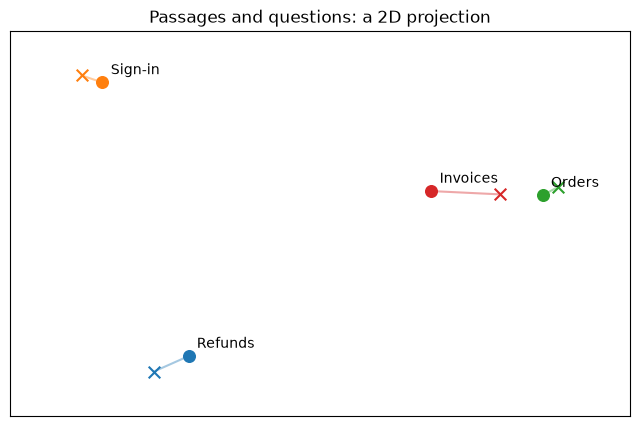

In [13]:
vectors = np.vstack([document_vectors, query_vectors])
centered = vectors - vectors.mean(axis=0)
_, _, principal_axes = np.linalg.svd(centered, full_matrices=False)
points = centered @ principal_axes[:2].T

fig, ax = plt.subplots(figsize=(8, 5))
for index, label in enumerate(["Refunds", "Sign-in", "Orders", "Invoices"]):
    pair = points[[index, index + len(passages)]]
    ax.plot(*pair.T, color=f"C{index}", alpha=0.4)
    ax.scatter(*pair[0], color=f"C{index}", s=70)
    ax.scatter(*pair[1], color=f"C{index}", marker="x", s=70)
    ax.annotate(label, pair[0], xytext=(6, 6), textcoords="offset points")
ax.set(title="Passages and questions: a 2D projection", xticks=[], yticks=[])
ax.margins(0.15)
plt.show()


Look for nearby question/passage pairs, but do not judge retrieval quality from this picture. The projection can distort distances. The evaluation below uses the original vectors.

## 3 · Check retrieval quality

**hit@1** is the fraction of questions with the answer first. **MRR** averages the reciprocal answer rank: rank 1 contributes 1, rank 2 contributes ½. Reuse the existing scores; this step makes no API requests.

In [14]:
def metrics(
    similarities: np.ndarray, passage_ids: list[str], expected_answers: list[str]
) -> tuple[float, float]:
    """Return hit@1 and MRR for the expected answer to each question."""
    ranks = []
    for row, answer in zip(similarities, expected_answers, strict=True):
        ranked_ids = [passage_ids[index] for index in np.argsort(-row, stable=True)]
        ranks.append(ranked_ids.index(answer) + 1)
    answer_ranks = np.array(ranks)
    return float(np.mean(answer_ranks == 1)), float(np.mean(1 / answer_ranks))


In [15]:
print(f"{'model':<34} {'hit@1':>6} {'MRR':>6}")
hit, mrr = metrics(scores, passage_ids, expected_answers)
print(f"{MODEL:<34} {hit:6.2f} {mrr:6.3f}")


model                               hit@1    MRR
ReOpenly/Qwen3-Embedding-0.6B        1.00  1.000


A hit@1 of 1 means every expected answer ranked first in this sample. Four illustrative questions explain the calculation; they do not establish quality on new data or a training gain. Use your own held-out questions before choosing a model.

## 4 · Compare a hosted model (optional)

After training and hosting your model, set `YOUR_MODEL` and `PROJECT` in the settings, then rerun. This adds **two embedding requests**. The base and hosted model are evaluated on the same passages and held-out questions.

In [16]:
if YOUR_MODEL:
    with OpenAI(
        api_key=API_KEY, base_url=f"{BASE_URL}/projects/{PROJECT}/openai/v1",
        max_retries=0, timeout=300,
    ) as hosted:
        documents = embed(
            list(passages.values()), input_type="document", model=YOUR_MODEL, api=hosted
        )
        queries = embed(questions, input_type="query", model=YOUR_MODEL, api=hosted)
    hit, mrr = metrics(queries @ documents.T, passage_ids, expected_answers)
    print(f"{YOUR_MODEL:<34} {hit:6.2f} {mrr:6.3f}")
else:
    print("Hosted comparison skipped. Set YOUR_MODEL after training and hosting.")


qwen3-embedding-0-6b-job-3           1.00  1.000


## 5 · Report searches for review (optional)

Choose a disposable embedding dataset. Set `REOPENLY_PROJECT`, `REOPENLY_DATASET_ID` and `REOPENLY_REPORT_SEARCHES=1`, then rerun. This adds **one embedding request** and **four persistent feedback events**. Reporting itself is free; each rerun adds new events. These searches differ from the held-out questions. Open Search feedback, mark useful results **+ Positive**, then add training pairs. If delivery is uncertain, retain the same event id and payload before retrying.

In [17]:
searches = [
    "How long do refunds take to arrive?",
    "reset 2fa without phone",
    "bulk export orders csv",
    "invoice missing company name"
]


In [18]:
def validate_dataset(api: httpx.Client, dataset_id: int) -> None:
    """Refuse a missing, archived or non-embedding feedback destination."""
    datasets = api.get("/datasets").raise_for_status().json()["data"]
    active = any(
        dataset["id"] == dataset_id and dataset["kind"] == "embedding"
        and not dataset.get("archived_at")
        for dataset in datasets
    )
    if not active:
        raise ValueError("Choose an active embedding dataset in this project.")


In [19]:
def ranked_results(scores: np.ndarray, passages: dict[str, str]) -> list[dict[str, object]]:
    """Describe every passage in descending similarity order."""
    passage_ids = list(passages)
    results = []
    for rank, index in enumerate(np.argsort(-scores, stable=True), start=1):
        passage_id = passage_ids[index]
        results.append({
            "rank": rank,
            "text": passages[passage_id],
            "metadata": {
                "score": float(scores[index]), "external_id": passage_id,
            },
        })
    return results


In [20]:
if REPORT_SEARCHES:
    with httpx.Client(
        base_url=f"{BASE_URL}/v1/projects/{PROJECT}",
        headers={"Authorization": f"Bearer {API_KEY}"}, timeout=300,
    ) as api:
        validate_dataset(api, int(DATASET_ID))
        search_scores = embed(searches, input_type="query") @ document_vectors.T
        for query, row in zip(searches, search_scores, strict=True):
            event = {
                "event_id": f"cookbook-{uuid4().hex}",
                "model": MODEL,
                "query": query,
                "metadata": {"occurred_at": datetime.now(timezone.utc).isoformat()},
                "results": ranked_results(row, passages),
            }
            api.post(f"/datasets/{DATASET_ID}/retrieval-events", json=event).raise_for_status()
            print(f"Reported: {query}")
else:
    print("Reporting skipped. Enable REPORT_SEARCHES to save four demo searches.")


Reported: How long do refunds take to arrive?


Reported: reset 2fa without phone


Reported: bulk export orders csv


Reported: invoice missing company name


## Try another question

Keep `YOUR_MODEL` empty and `REPORT_SEARCHES` disabled. Replace one question in `test_questions` with a paraphrase, keeping its expected passage id. Rerun from the `passage_ids = list(passages)` cell through the evaluation. This makes **two additional embedding requests**, stores no feedback, and lets you inspect how the ranking and metrics respond to different wording.